<a href="https://colab.research.google.com/github/mers2727/mineria-textos-esperanto/blob/main/Practica_Esperanto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de textos en Esperanto
**Minería de Textos · 4º INF-A · 2026/2027**
**Equipo:** Mikel Echarri Richard · Joaquín Álvarez Julia · Víctor Hernández Enciso

## Índice
1. Configuración
2. Fase 1 — Dataset
3. Fase 2 — Modelo de NLP
4. Fase 3 — Clasificación y páginas web
5. Conclusiones


## 1. Configuración
Todos los parámetros que se pueden cambiar están en la celda siguiente. La semilla está fijada para que el resultado sea reproducible.

In [ ]:
# ===== 1. Configuración =====
# Librerías estándar de Python
import re                  # expresiones regulares: limpieza de texto y tokenizador
import time                # pausas entre peticiones a Wikipedia
import random              # muestreos aleatorios (con semilla)
import unicodedata         # normalizar letras del esperanto (ĉ, ĝ, ŭ...)
from collections import Counter   # contar palabras

# Librerías vistas en clase (apartado 3.1 del enunciado)
import numpy as np
import pandas as pd        # tablas y el CSV del dataset
import requests            # peticiones al API de Wikipedia y a páginas web
import matplotlib.pyplot as plt   # gráficos
import sklearn             # modelo de clasificación (Fase 3)
import bs4                 # BeautifulSoup: web scraping (Fase 3)

# Semilla fija: los muestreos y el modelo darán siempre el mismo resultado
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# True: genera el dataset desde Wikipedia. False: lee el CSV ya publicado en GitHub
GENERAR_DATASET = False
URL_REPO = "https://raw.githubusercontent.com/mers2727/mineria-textos-esperanto/main/"

# Versiones de las librerías, porque algún resultado puede variar entre versiones
for nombre, modulo in [("pandas", pd), ("numpy", np), ("requests", requests),
                       ("scikit-learn", sklearn), ("beautifulsoup4", bs4)]:
    print(f"{nombre:15s} {modulo.__version__}")

pandas          2.2.3
numpy           2.4.6
requests        2.32.4
scikit-learn    1.6.1
beautifulsoup4  4.13.5


## 2. Fase 1 — Dataset

### 2.1 Selección de temáticas
Elegimos **`fiziko` (física), `kemio` (química) y `biologio` (biología)**, uno de los ejemplos del enunciado.

* **Son cercanas:** las tres son ciencias naturales y comparten vocabulario (*energio*, *molekulo*, *atomo*, *akvo*),
  así que el problema no es trivial.
* **Hay datos suficientes:** antes de decidir lo comprobamos con el API de Wikipedia en Esperanto (celda siguiente).
* **Riesgo que asumimos:** hay temas a caballo entre dos clases (bioquímica, biofísica). Los trataremos en la limpieza.

In [ ]:
# ===== 2.1 Comprobación de que hay datos =====
API = "https://eo.wikipedia.org/w/api.php"

# Wikipedia pide que los programas se identifiquen con un User-Agent con contacto
sesion = requests.Session()
sesion.headers["User-Agent"] = ("CUNEF-MineriaTextos/1.0 (practica academica; "
                                "https://github.com/mers2727/mineria-textos-esperanto)")

CATEGORIAS = {"fiziko": "Fiziko", "kemio": "Kemio", "biologio": "Biologio"}   # etiqueta -> categoría de Wikipedia


def contar_miembros(categoria):
    """Cuántos artículos y subcategorías cuelgan directamente de una categoría (máx. 500, solo para explorar)."""
    parametros = {"action": "query", "list": "categorymembers", "cmtitle": f"Kategorio:{categoria}",
                  "cmtype": "page|subcat", "cmlimit": 500, "format": "json"}
    try:
        datos = sesion.get(API, params=parametros, timeout=30).json()
    except (requests.RequestException, ValueError):
        return None, None                      # si Wikipedia falla, el cuaderno sigue
    miembros = datos.get("query", {}).get("categorymembers", [])
    articulos = sum(1 for m in miembros if m["ns"] == 0)       # ns 0 = artículo
    subcategorias = sum(1 for m in miembros if m["ns"] == 14)  # ns 14 = categoría
    return articulos, subcategorias


exploracion = pd.DataFrame(
    [(etiqueta, *contar_miembros(cat)) for etiqueta, cat in CATEGORIAS.items()],
    columns=["clase", "artículos directos", "subcategorías"]).set_index("clase")
print(exploracion)

          artículos directos  subcategorías
clase                                      
fiziko                   256             24
kemio                    150              6
biologio                 114             65


### 2.2 Descarga de artículos
**Fuente:** API de Wikipedia en Esperanto (`eo.wikipedia.org`).

* **Qué artículos:** los de la categoría de cada clase y los de sus subcategorías (un nivel). En `kemio` añadimos
  más categorías de partida porque solo tiene 6 subcategorías.
* **Subcategorías excluidas:** las que no son la ciencia en sí (biografías, listas, premios, historia) y las que
  mezclan dos clases (bioquímica, biofísica, química cuántica).
* **Artículos ambiguos:** si un artículo aparece en dos clases, lo quitamos de ambas.
* **Tamaño:** como mucho 250 artículos por clase, elegidos al azar con la semilla.
* **Robustez:** si Wikipedia responde "demasiadas peticiones" (429) o falla la red, esperamos y reintentamos.

In [ ]:
# ===== 2.2 Funciones de descarga =====
# Categorías de Wikipedia de las que partimos para cada clase
SEMILLAS = {
    "fiziko":   ["Fiziko"],
    "kemio":    ["Kemio", "Konceptoj en kemio", "Kemiaj elementoj", "Organika kemio", "Neorganika kemio"],
    "biologio": ["Biologio"],
}
# Si el nombre de una subcategoría contiene alguno de estos trozos, no se usa
SUBCATS_EXCLUIDAS = ["biograf", "listoj", "fizikistoj", "kemiistoj", "biologoj", "historio", "organizaĵoj",
                     "premioj", "biokemio", "biofiziko", "kvantuma kemio", "faŭno", "flaŭro"]
MAX_ARTICULOS_POR_CLASE = 250
PAUSA = 0.3    # segundos entre descargas, para no saturar Wikipedia


def pedir(parametros, intentos=4):
    """Petición al API de Wikipedia. Reintenta si hay error; devuelve None si no lo consigue."""
    parametros = {**parametros, "format": "json", "formatversion": 2}
    for intento in range(intentos):
        try:
            respuesta = sesion.get(API, params=parametros, timeout=30)
            if respuesta.status_code in (429, 503):        # "demasiadas peticiones" o servidor ocupado
                time.sleep(2 * 2 ** intento)               # esperamos 2, 4, 8... segundos
                continue
            respuesta.raise_for_status()                   # otros errores HTTP -> excepción
            return respuesta.json()
        except (requests.RequestException, ValueError):
            time.sleep(2 ** intento)
    return None


def miembros(categoria, tipo):
    """Títulos de los artículos (tipo='page') o subcategorías (tipo='subcat') de una categoría.
    El API devuelve los resultados por tandas: seguimos pidiendo mientras haya 'continue'."""
    titulos, continuar = [], {}
    while True:
        datos = pedir({"action": "query", "list": "categorymembers", "cmtitle": f"Kategorio:{categoria}",
                       "cmtype": tipo, "cmlimit": 500, **continuar})
        if datos is None or "error" in datos:              # sin conexión o la categoría no existe
            return titulos
        titulos += [m["title"] for m in datos["query"]["categorymembers"]]
        if "continue" not in datos:
            return titulos
        continuar = datos["continue"]


def articulos_de_clase(semillas):
    """Artículos de las categorías semilla y de sus subcategorías (un nivel), sin las excluidas."""
    articulos = set()
    for categoria in semillas:
        articulos.update(miembros(categoria, "page"))
        for sub in miembros(categoria, "subcat"):
            nombre = sub.split(":", 1)[1]                  # "Kategorio:Optiko" -> "Optiko"
            if not any(trozo in nombre.lower() for trozo in SUBCATS_EXCLUIDAS):
                articulos.update(miembros(nombre, "page"))
    return articulos


def texto_de_articulo(titulo):
    """Texto plano de un artículo (sin HTML ni marcado wiki). Devuelve '' si falla."""
    time.sleep(PAUSA)
    datos = pedir({"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": titulo})
    if datos is None:
        return ""
    paginas = datos.get("query", {}).get("pages", [])
    return paginas[0].get("extract", "") if paginas else ""

In [ ]:
# ===== 2.2 Descarga (solo si GENERAR_DATASET = True) =====
if GENERAR_DATASET:
    inicio = time.time()
    candidatos = {clase: articulos_de_clase(semillas) for clase, semillas in SEMILLAS.items()}

    # Un artículo que está en dos clases es ambiguo: lo quitamos de todas
    conteo = Counter(titulo for articulos in candidatos.values() for titulo in articulos)
    ambiguos = {titulo for titulo, veces in conteo.items() if veces > 1}

    rng = random.Random(SEMILLA)
    textos = {}                                            # clase -> {título: texto}
    for clase, articulos in candidatos.items():
        lista = sorted(articulos - ambiguos)               # sorted: mismo orden en cada ejecución
        rng.shuffle(lista)
        elegidos = lista[:MAX_ARTICULOS_POR_CLASE]
        textos[clase] = {titulo: texto_de_articulo(titulo) for titulo in elegidos}
        vacios = sum(1 for texto in textos[clase].values() if not texto)
        print(f"{clase:9s} {len(articulos):5d} candidatos -> {len(elegidos)} descargados ({vacios} vacíos)")

    print(f"Artículos ambiguos eliminados: {len(ambiguos)}")
    print(f"Tiempo: {time.time() - inicio:.0f} s")

### 2.3 División en párrafos y limpieza
Cada línea del texto de un artículo es un párrafo. Para cumplir el **contrato de datos**:

* **Limpieza:** quitamos referencias (`[1]`), URLs, restos de HTML y comillas dobles, y cambiamos `;` por `,`.
* **Secciones que no son prosa:** descartamos *Referencoj*, *Eksteraj ligiloj*, *Vidu ankaŭ*, etc.
* **Párrafos válidos:** al menos 100 caracteres y 15 palabras, que empiecen como una frase (mayúscula o cifra) y
  acaben en punto, y que sean texto en su mayoría (no tablas ni fórmulas).
* **Tope por artículo:** como mucho 10 párrafos por artículo, elegidos al azar. Así ningún artículo largo domina
  su clase, y su ruido pesa menos.
* **Repetidos:** si un mismo párrafo aparece en dos clases, lo quitamos; si se repite en la misma clase, dejamos uno.

In [ ]:
# ===== 2.3 Funciones de limpieza =====
SECCIONES_EXCLUIDAS = {"referencoj", "eksteraj ligiloj", "vidu ankaŭ", "notoj", "literaturo",
                       "bibliografio", "fontoj", "ligiloj", "legu ankaŭ"}
LONGITUD_MIN = 100               # caracteres
PALABRAS_MIN = 15
MAX_PARRAFOS_POR_ARTICULO = 10


def limpiar_parrafo(parrafo):
    """Deja el párrafo limpio según el contrato de datos."""
    parrafo = unicodedata.normalize("NFC", parrafo)               # ĉ siempre como una sola letra
    parrafo = re.sub(r"\[[^\]]*\]", "", parrafo)                   # referencias: [1], [citaĵo bezonata]
    parrafo = re.sub(r"https?://\S+|www\.\S+", "", parrafo)        # enlaces
    parrafo = re.sub(r"<[^>]+>", "", parrafo)                      # restos de etiquetas HTML
    parrafo = re.sub(r"\(\s*\)", "", parrafo)                      # paréntesis que se quedan vacíos
    parrafo = parrafo.replace(";", ",").replace('"', "")           # ';' es el separador del CSV
    parrafo = re.sub(r"\s+", " ", parrafo).strip()                 # espacios repetidos
    return re.sub(r"\s+([,.:!?])", r"\1", parrafo)                 # espacio antes de un signo


def es_parrafo_valido(parrafo):
    """True si es un párrafo de verdad: largo, frase completa y casi todo letras."""
    if len(parrafo) < LONGITUD_MIN or len(parrafo.split()) < PALABRAS_MIN:
        return False
    if not (parrafo[0].isupper() or parrafo[0].isdigit() or parrafo[0] in "«("):
        return False                                               # empieza en minúscula: frase cortada
    if parrafo[-1] not in ".!?»)":
        return False                                               # no acaba como una frase
    return sum(c.isalpha() for c in parrafo) / len(parrafo) >= 0.7  # tablas y fórmulas tienen pocas letras


def parrafos_de_texto(texto):
    """Párrafos válidos de un artículo, saltando las secciones que no son prosa."""
    resultado, seccion = [], ""
    for linea in texto.split("\n"):
        linea = linea.strip()
        encabezado = re.fullmatch(r"=+\s*(.*?)\s*=+", linea)      # "== Historio =="
        if encabezado:
            seccion = encabezado.group(1).lower()
        elif linea and seccion not in SECCIONES_EXCLUIDAS:
            parrafo = limpiar_parrafo(linea)
            if es_parrafo_valido(parrafo):
                resultado.append(parrafo)
    return resultado


# Pruebas rápidas de la limpieza
assert limpiar_parrafo("La atomo [1] estas malgranda; vidu https://x.org .") == "La atomo estas malgranda, vidu."
assert not es_parrafo_valido("notis ke ĉi tiu procezo estas grava sub kondiĉoj kiel altaj temperaturoj kaj premoj en la naturo.")
print("Pruebas de limpieza: OK")

Pruebas de limpieza: OK


In [ ]:
# ===== 2.3 Construcción de la tabla de párrafos =====
if GENERAR_DATASET:
    filas = [{"text": parrafo, "class": clase, "article": titulo}
             for clase, articulos in textos.items()
             for titulo, texto in articulos.items()
             for parrafo in parrafos_de_texto(texto)]
    df_completo = pd.DataFrame(filas)

    # Repetidos: si un párrafo está en dos clases se quita; si no, se deja una copia
    en_varias_clases = df_completo.groupby("text")["class"].transform("nunique") > 1
    df_completo = df_completo[~en_varias_clases].drop_duplicates(subset="text").reset_index(drop=True)
    print("Párrafos válidos por clase:  ", df_completo["class"].value_counts().to_dict())

    # Tope por artículo: barajamos (con semilla) y nos quedamos con los 10 primeros de cada artículo
    df_tope = (df_completo.sample(frac=1, random_state=SEMILLA)
               .groupby("article").head(MAX_PARRAFOS_POR_ARTICULO).reset_index(drop=True))
    print("Tras el tope por artículo:   ", df_tope["class"].value_counts().to_dict())
    print("Artículos con párrafos:      ", df_tope.groupby("class")["article"].nunique().to_dict())

In [ ]:
# ===== 2.2 Leer el dataset publicado =====
df_publicado = None
if not GENERAR_DATASET:
    try:
        df_publicado = pd.read_csv(URL_REPO + "dataset_con_articulos.csv", sep=";", encoding="utf-8")
        print(f"Dataset leído de GitHub: {len(df_publicado)} párrafos")
    except Exception as error:                     # sin conexión, fichero inexistente, CSV roto...
        print(f"No se pudo leer el CSV de GitHub ({type(error).__name__}). Lo generamos desde Wikipedia.")
        GENERAR_DATASET = True                     # plan B: las celdas siguientes lo generan

Dataset leído de GitHub: 1800 párrafos


### 2.4 Dataset final y contrato de datos
* **Equilibrado:** 600 párrafos por clase, elegidos al azar con la semilla. Con clases del mismo tamaño, accuracy y
  F1 macro son fáciles de interpretar, y el modelo no se inclina hacia la clase más grande.
* **Dos ficheros:** `dataset.csv` es el contrato (`text;class`). `dataset_con_articulos.csv` añade la columna
  `article`, que necesitaremos en la Fase 3 para que ningún artículo tenga párrafos en train y en test a la vez.
* **Comprobación del contrato:** lo verificamos con `assert` releyendo el fichero guardado.
* **Publicación:** ambos ficheros están en GitHub; con `GENERAR_DATASET = False` se leen de ahí.

'dataset.csv' cumple el contrato: 1800 párrafos, {'kemio': 600, 'fiziko': 600, 'biologio': 600}


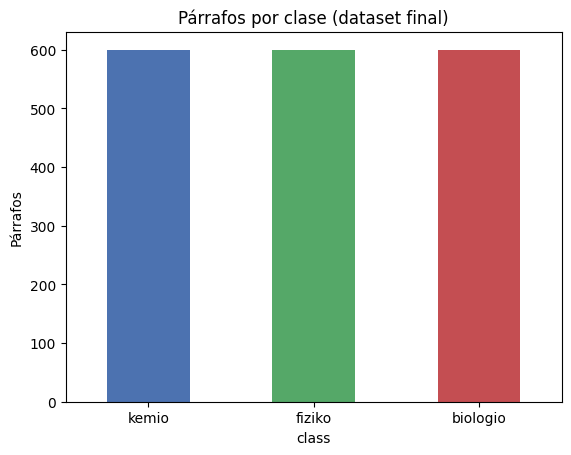

In [ ]:
# ===== 2.4 Equilibrado, guardado y comprobación del contrato =====
ARCHIVO_DATASET = "dataset.csv"                          # contrato: text;class
ARCHIVO_DATASET_ARTICULOS = "dataset_con_articulos.csv"  # igual + columna article
PARRAFOS_POR_CLASE = 600


def equilibrar(df, n):
    """Mismo número de párrafos en cada clase (n, o el de la clase más pequeña si tiene menos)."""
    n = min(n, df["class"].value_counts().min())
    return (df.groupby("class").sample(n=n, random_state=SEMILLA)   # n al azar de cada clase
              .sample(frac=1, random_state=SEMILLA)                 # mezclamos las clases
              .reset_index(drop=True))


df_final = equilibrar(df_tope, PARRAFOS_POR_CLASE) if GENERAR_DATASET else df_publicado

# Guardamos los dos ficheros (siempre, para poder comprobar el contrato sobre el fichero real)
df_final[["text", "class"]].to_csv(ARCHIVO_DATASET, sep=";", index=False, encoding="utf-8")
df_final[["text", "class", "article"]].to_csv(ARCHIVO_DATASET_ARTICULOS, sep=";", index=False, encoding="utf-8")

# Comprobación del contrato de datos sobre el fichero guardado
releido = pd.read_csv(ARCHIVO_DATASET, sep=";", encoding="utf-8")
assert list(releido.columns) == ["text", "class"], "cabecera incorrecta"
assert len(releido) == len(df_final), "alguna fila se ha roto al guardar"
assert not releido["text"].str.contains(";").any(), "hay párrafos con ';'"
assert not releido["text"].str.contains(r"https?://|<[^>]+>|\[\d+\]").any(), "quedan links, HTML o referencias"
assert releido["class"].value_counts().min() >= 300, "alguna clase tiene menos de 300 párrafos"
print(f"'{ARCHIVO_DATASET}' cumple el contrato: {len(releido)} párrafos, {releido['class'].value_counts().to_dict()}")

ax = releido["class"].value_counts().plot(kind="bar", rot=0, color=["#4c72b0", "#55a868", "#c44e52"])
ax.set_title("Párrafos por clase (dataset final)")
ax.set_ylabel("Párrafos")
plt.show()

### 2.5 Ruido de etiquetas
Cada párrafo hereda la clase de su artículo, pero no todos los párrafos hablan de esa ciencia:

* **Párrafos genéricos:** solo tienen sentido dentro de su artículo (*"Ĝi estis fondita en 1950"*).
* **Párrafos de otro tema:** biografías de científicos, historia de una empresa o de un descubrimiento.
* **Párrafos entre dos ciencias:** química dentro de un artículo de física, o al revés.

Ya lo reducimos al construir el dataset (subcategorías excluidas, artículos ambiguos fuera, tope por artículo).
Para medir el que queda usamos **indicadores aproximados** (no sabemos la tasa real sin etiquetar a mano):
1. Párrafos **cortos** (menos de 25 palabras): poca información.
2. Párrafos que **empiezan por una anáfora** (*Ĝi, Ili, Tio...*): dependen del contexto del artículo.
3. Párrafos que **mencionan un año**: suelen ser historia, no la ciencia en sí.
4. Párrafos con **léxico biográfico o de empresa** (*naskiĝis, mortis, fondis, firmao...*).

Además revisamos a mano una **muestra aleatoria** de 5 párrafos por clase.

In [ ]:
# ===== 2.5 Medida aproximada del ruido =====
PALABRAS_CORTO = 25
ANAFORA = r"^(?:Ĝi|Ili|Li|Ŝi|Tio|Tiuj?|Tie|Tiam|Ĝiaj?|Iliaj?)\b"     # empieza por un pronombre o "tio, tie..."
ANIO = r"\b(?:1[5-9]\d\d|20[0-2]\d)\b"                                 # años entre 1500 y 2029
OTRO_TEMA = r"(?i)\b(?:naskiĝis|mortis|fondis|fondita|profesoro|universitato|premio|firmao|entrepreno)"


def tabla_ruido(df):
    """Indicadores de ruido por clase, en % de párrafos."""
    palabras = df["text"].str.split().str.len()
    indicadores = pd.DataFrame({
        f"% cortos (<{PALABRAS_CORTO} palabras)": palabras < PALABRAS_CORTO,
        "% empieza por anáfora": df["text"].str.contains(ANAFORA),
        "% menciona un año": df["text"].str.contains(ANIO),
        "% léxico biográfico/empresa": df["text"].str.contains(OTRO_TEMA),
    })
    tabla = indicadores.groupby(df["class"]).mean().mul(100).round(1)   # media de True/False = proporción
    tabla.insert(0, "palabras/párrafo", palabras.groupby(df["class"]).mean().round(1))
    tabla.insert(0, "artículos", df.groupby("class")["article"].nunique())
    return tabla


display(tabla_ruido(df_final))

print("\nMuestra para revisar a mano: ¿se reconoce la clase leyendo solo el párrafo?\n")
for clase, grupo in df_final.groupby("class"):
    print(f"--- {clase.upper()} ---")
    for i, (_, fila) in enumerate(grupo.sample(n=5, random_state=SEMILLA).iterrows(), start=1):
        print(f"{i}. ({fila['article']}) {fila['text'][:200]}...")
    print()

,artículos,palabras/párrafo,% cortos (<25 palabras),% empieza por anáfora,% menciona un año,% léxico biográfico/empresa
class,,,,,,
biologio,226,52.5,14.8,4.3,12.2,3.2
fiziko,208,52.5,19.0,3.0,12.0,2.7
kemio,229,48.5,14.8,5.5,14.2,3.2



Muestra para revisar a mano: ¿se reconoce la clase leyendo solo el párrafo?

--- BIOLOGIO ---
1. (Dieta suplemento) Estas pli ol 50.000 dietaj suplementoj disponeblaj kaj estas konsumitaj de ĉirkaŭ la duono de la usona plenkreska populacio. Tiuj produktoj ne intencas eviti aŭ trakti malsanon kaj ĉe kelkaj cirkonsta...
2. (Arboskeleto) Arboskeletoj estas nemalhaveblaj por diversaj birdospecioj. Akvo-ĉasbirdoj kiaj fiŝaglo aŭ alcedinedoj troveblas proksime de akvo, ripozante sur arboskeleto, aŭ manĝante sur ĝi fiŝkaptaĵon. La arboske...
3. (Habitatodetruo) Per simplaj terminoj, kiam habitato detruiĝas, plantoj, animaloj kaj aliaj organismoj kiuj estis okupintaj la habitaton suferas malpliigitan ŝarĝokapablon tiel ke la diversaj populacioj malpliiĝas kaj...
4. (La Akvariinfanoj) La Akvariinfanoj, estas libreto verkita de Willem Verloren van Themaat kaj eldonita en 1976 de Vulpo-Libroj el Lelystad (Nederlando). Laŭ la subtitolo temas pri sciencfikcia romano. La kovrilon kaj la...
5. (Mikr

**Lectura de los resultados.**
* **Indicadores:** entre un 15 y un 19 % de párrafos cortos, un 3–5,5 % que empiezan por una anáfora y un ~3 % con
  léxico biográfico o de empresa, parecido en las tres clases. El 12–14 % que menciona un año sobreestima el ruido,
  porque muchos párrafos científicos citan la fecha de un descubrimiento.
* **Muestra a mano (15 párrafos):** 10 son claramente de su clase, 1 es dudoso y 4 son ruido:
  * de otro tema: un suplemento dietético y un libro de ciencia ficción en `biologio`, y una biografía
    (*Andrés Manuel del Río*) en `kemio`;
  * entre dos ciencias: una oxidación (química) en un artículo de física (*Metastabileco*);
  * un fragmento de lista que pasó el filtro por empezar con una cifra (*Specoj de betono*, en `kemio`).
* **Conclusión:** el ruido es sobre todo de otro tema o entre dos ciencias, no solo párrafos genéricos. La muestra
  es pequeña, así que no da una tasa fiable: solo dice por dónde entra el ruido. Mejoras posibles: filtrar por las
  categorías de cada artículo (biografías, libros, empresas) y descartar los párrafos que empiezan con una cifra.

## 3. Fase 2 — Modelo de NLP para Esperanto
Construimos desde cero (sin spaCy, NLTK ni Stanza) un modelo **basado en reglas** con un API parecido al de spaCy:

    nlp = Esperanto()
    doc = nlp("La juna instruistino legas interesan libron.")
    for token in doc:
        print(token.text, token.lemma_, token.pos_, token.is_stop)

Las piezas, en orden: **normalización → tokenizador → POS y lema → stop-words → objetos `Doc` y `Token`**.

### 3.1 Normalización y tokenizador
* **Normalización:** Unicode NFC, para que *ĉ* sea siempre una sola letra y no *c* más un acento suelto, y un
  único tipo de apóstrofo.
* **Tokenizador:** una lista de reglas, de la más específica a la más general (tema 2.2: gana la regla más compleja
  que encaje):
  1. **abreviaturas** (*ekz.*, *t.e.*, *ktp.*): el punto forma parte del token;
  2. **números** (*1950*, *3,14*): la coma o el punto decimal no los parten;
  3. **palabras**: letras, incluidas *ĉ ĝ ĥ ĵ ŝ ŭ*, con guiones o apóstrofos dentro (*Sud-Afriko*);
  4. **cualquier otro signo** es un token de puntuación.
* **Limitación:** las fórmulas químicas se parten (*H2O* → *H*, *2*, *O*).

In [ ]:
# ===== 3.1 Normalización y tokenizador =====
ABREVIATURAS = {"ekz.", "t.e.", "ktp.", "k.t.p.", "k.a.", "t.n."}   # ekzemple, tio estas, kaj tiel plu...
_abreviaturas = "|".join(re.escape(a) for a in sorted(ABREVIATURAS, key=len, reverse=True))

# Las reglas se prueban en orden: en cada posición del texto gana la primera alternativa que encaja
PATRON_TOKEN = re.compile(
    rf"(?<!\w)(?i:{_abreviaturas})"        # 1. abreviaturas (con su punto)
    r"|\d+(?:[.,]\d+)*"                    # 2. números: 1950, 3,14, 10.000
    r"|[^\W\d_]+(?:[-'][^\W\d_]+)*"        # 3. palabras: letras, con guion o apóstrofo en medio
    r"|[^\w\s]"                            # 4. cualquier otro signo: . , ( ) « » ...
)


def normalizar(texto):
    """Unicode NFC (ĉ = una sola letra) y un único tipo de apóstrofo."""
    return unicodedata.normalize("NFC", texto).replace("’", "'")


def tokenizar(texto):
    """Lista de tokens de un texto."""
    return PATRON_TOKEN.findall(normalizar(texto))


# Pruebas del tokenizador
assert tokenizar("La juna instruistino legas interesan libron.") == \
    ["La", "juna", "instruistino", "legas", "interesan", "libron", "."]
assert tokenizar("Ĉu vi legis 3,14 librojn?") == ["Ĉu", "vi", "legis", "3,14", "librojn", "?"]
assert tokenizar("Sud-Afriko estas granda, ekz. la urbo.") == \
    ["Sud-Afriko", "estas", "granda", ",", "ekz.", "la", "urbo", "."]
assert tokenizar("En 1950, ili venis.") == ["En", "1950", ",", "ili", "venis", "."]
assert tokenizar("c\u0302ielo") == ["ĉielo"]       # 'c' + acento combinante -> 'ĉ' gracias a NFC
print("Pruebas del tokenizador: OK")

# Ejemplo con un párrafo real del dataset
ejemplo = df_final["text"].iloc[0][:150]
print("\nTexto: ", ejemplo)
print("Tokens:", tokenizar(ejemplo))

Pruebas del tokenizador: OK

Texto:  Ramnozo estas natura karbonhidrato, monosaĥarido. Oni povas klasifiki ĝin aŭ kiel metil-pentozo, aŭ kiel 6-deoksi-heksozo. Malsame al plimulto de saka
Tokens: ['Ramnozo', 'estas', 'natura', 'karbonhidrato', ',', 'monosaĥarido', '.', 'Oni', 'povas', 'klasifiki', 'ĝin', 'aŭ', 'kiel', 'metil-pentozo', ',', 'aŭ', 'kiel', '6', '-', 'deoksi-heksozo', '.', 'Malsame', 'al', 'plimulto', 'de', 'saka']


### 3.2 Etiquetado gramatical (POS) y lematización
El Esperanto es regular: **la terminación de una palabra indica su categoría**, y de ella sale el lema.

| Terminación | Categoría (`pos_`) | Rasgos (`morph`) | Ejemplo → lema |
|---|---|---|---|
| `-o`, `-oj`, `-on`, `-ojn` | `NOUN` | número y caso | `librojn` → `libro` |
| `-a`, `-aj`, `-an`, `-ajn` | `ADJ` | número y caso | `interesan` → `interesa` |
| `-e`, `-en` | `ADV` | `-n` = dirección | `hejmen` → `hejme` |
| `-as`, `-is`, `-os`, `-us`, `-u`, `-i` | `VERB` (`AUX` si es *esti*) | tiempo y modo | `legis` → `legi` |

**Orden de las reglas** (la primera que encaja decide):
1. Signos → `PUNCT`. Cifras → `NUM`. Siglas en mayúsculas (*DNA*) y abreviaturas → `X`.
2. **Palabras cerradas** de la guía (artículo, pronombres, preposiciones, conjunciones, partículas). Van antes que
   las terminaciones porque muchas parecen tener una: `ĝis` parecería un verbo en `-is` y `pro` un sustantivo en `-o`.
3. **Correlativos** (*kiu, tio, ĉiam, nenie...*): 5 prefijos × 9 finales, generados con un bucle.
4. **Formas de los pronombres** (*min, mia, miajn*) y **numerales** (*tri, dudek, tricent*).
5. **Terminaciones** de la tabla, exigiendo una raíz de al menos 2 letras.
6. **Nombres propios:** mayúscula en mitad de frase → `PROPN` (*Einstein*, *Ulm*). Las palabras cerradas solo
   cuentan en minúscula o al inicio de frase: *Li* en mitad de frase es el litio, no "él".

**Limitaciones:** no descomponemos afijos (*mal-*, *-ist-*) ni participios (*leganta* queda como adjetivo con lema
*leganta*, no *legi*).

In [ ]:
# ===== 3.2 Palabras cerradas (vortetoj) de la guía de gramática =====
PRONOMBRES = {"mi", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni", "si", "ci"}
CERRADAS = {"la": "DET"}                                   # palabra -> categoría
CERRADAS.update({p: "PRON" for p in PRONOMBRES})
CERRADAS.update({p: "ADP" for p in [
    "al", "anstataŭ", "antaŭ", "apud", "ĉe", "ĉirkaŭ", "da", "de", "dum", "ekde", "ekster", "el", "en", "ĝis",
    "inter", "je", "kontraŭ", "krom", "kun", "laŭ", "malantaŭ", "malgraŭ", "per", "po", "por", "post", "preter",
    "pri", "pro", "sen", "sub", "super", "sur", "tra", "trans"]})
CERRADAS.update({p: "CCONJ" for p in ["kaj", "aŭ", "sed", "nek"]})
CERRADAS.update({p: "SCONJ" for p in ["ke", "ĉar", "se", "ol", "kvankam", "kvazaŭ"]})
CERRADAS.update({p: "ADV" for p in [
    "tre", "tro", "pli", "plej", "plu", "jam", "ankoraŭ", "ankaŭ", "nun", "tuj", "hodiaŭ", "hieraŭ", "morgaŭ",
    "for", "apenaŭ", "baldaŭ", "preskaŭ", "eĉ", "almenaŭ", "nur", "mem", "tamen", "do", "ĵus"]})
CERRADAS.update({p: "PART" for p in ["ne", "ĉu", "ja", "jen", "ajn", "ju", "des", "ĉi"]})
CERRADAS.update({p: "INTJ" for p in ["jes", "ha", "ho", "nu", "ve", "adiaŭ"]})

# Correlativos: prefijo + final (+ flexión). forma -> (categoría, lema)
PREFIJOS_CORRELATIVOS = ["ki", "ti", "i", "ĉi", "neni"]
FINALES_CORRELATIVOS = {"o": ("PRON", ["", "n"]), "u": ("PRON", ["", "j", "n", "jn"]),
                        "a": ("DET", ["", "j", "n", "jn"]), "es": ("DET", [""]), "e": ("ADV", ["", "n"]),
                        "am": ("ADV", [""]), "al": ("ADV", [""]), "el": ("ADV", [""]), "om": ("ADV", [""])}
CORRELATIVOS = {}
for prefijo in PREFIJOS_CORRELATIVOS:
    for final, (categoria, flexiones) in FINALES_CORRELATIVOS.items():
        for flexion in flexiones:
            CORRELATIVOS[prefijo + final + flexion] = (categoria, prefijo + final)

# Formas de los pronombres: acusativo (min) y posesivos (mia, miaj, mian, miajn). forma -> (categoría, lema)
FORMAS_PRONOMBRE = {}
for p in PRONOMBRES:
    FORMAS_PRONOMBRE[p + "n"] = ("PRON", p)
    for flexion in ["", "j", "n", "jn"]:
        FORMAS_PRONOMBRE[p + "a" + flexion] = ("DET", p + "a")

# Numerales: una o varias raíces seguidas (tri, dek, dudek, tricent...)
RE_NUMERAL = re.compile(r"(?:nul|unu|du|tri|kvar|kvin|ses|sep|ok|naŭ|dek|cent|mil)+")

print(f"{len(CERRADAS)} palabras cerradas, {len(CORRELATIVOS)} formas de correlativos, "
      f"{len(FORMAS_PRONOMBRE)} formas de pronombres")

94 palabras cerradas, 85 formas de correlativos, 50 formas de pronombres


In [ ]:
# ===== 3.2 POS y lema de una palabra =====
# (terminación, categoría, final del lema, rasgos). De la más larga a la más corta: 'ojn' antes que 'o'
TERMINACIONES = [
    ("ojn", "NOUN", "o", {"Number": "Plur", "Case": "Acc"}),
    ("oj",  "NOUN", "o", {"Number": "Plur", "Case": "Nom"}),
    ("on",  "NOUN", "o", {"Number": "Sing", "Case": "Acc"}),
    ("o",   "NOUN", "o", {"Number": "Sing", "Case": "Nom"}),
    ("ajn", "ADJ",  "a", {"Number": "Plur", "Case": "Acc"}),
    ("aj",  "ADJ",  "a", {"Number": "Plur", "Case": "Nom"}),
    ("an",  "ADJ",  "a", {"Number": "Sing", "Case": "Acc"}),
    ("a",   "ADJ",  "a", {"Number": "Sing", "Case": "Nom"}),
    ("en",  "ADV",  "e", {"Case": "Acc"}),                     # dirección: hejmen
    ("e",   "ADV",  "e", {}),
    ("as",  "VERB", "i", {"Mood": "Ind", "Tense": "Pres", "VerbForm": "Fin"}),
    ("is",  "VERB", "i", {"Mood": "Ind", "Tense": "Past", "VerbForm": "Fin"}),
    ("os",  "VERB", "i", {"Mood": "Ind", "Tense": "Fut", "VerbForm": "Fin"}),
    ("us",  "VERB", "i", {"Mood": "Cnd", "VerbForm": "Fin"}),
    ("u",   "VERB", "i", {"Mood": "Imp", "VerbForm": "Fin"}),
    ("i",   "VERB", "i", {"VerbForm": "Inf"}),
]


def analizar_palabra(palabra, inicio_de_frase=False):
    """(pos, lema, rasgos) de un token, aplicando las reglas en orden."""
    bajo = palabra.lower()

    # 1. Signos, números, siglas y abreviaturas
    if not any(c.isalnum() for c in palabra):
        return "PUNCT", palabra, {}
    if any(c.isdigit() for c in palabra):
        return "NUM", palabra, {}
    if bajo in ABREVIATURAS or (len(palabra) > 1 and palabra.isupper()):
        return "X", bajo, {}

    # 2-4. Palabras cerradas, correlativos, pronombres y numerales (solo en minúscula o a inicio de frase)
    if palabra.islower() or inicio_de_frase:
        if bajo in CERRADAS:
            return CERRADAS[bajo], bajo, {}
        if bajo in CORRELATIVOS:
            categoria, lema = CORRELATIVOS[bajo]
            return categoria, lema, {}
        if bajo in FORMAS_PRONOMBRE:
            categoria, lema = FORMAS_PRONOMBRE[bajo]
            return categoria, lema, {}
        if RE_NUMERAL.fullmatch(bajo):
            return "NUM", bajo, {}

    # 5. Terminaciones (raíz de al menos 2 letras)
    for final, categoria, final_lema, rasgos in TERMINACIONES:
        raiz = bajo[:-len(final)]
        if bajo.endswith(final) and len(raiz) >= 2:
            lema = raiz + final_lema
            if lema == "esti":
                categoria = "AUX"
            # 6. Mayúscula en mitad de frase: nombre propio (Parizon -> PROPN, lema parizo)
            if palabra[0].isupper() and not inicio_de_frase:
                return "PROPN", lema if categoria in ("NOUN", "ADJ") else bajo, dict(rasgos)
            return categoria, lema, dict(rasgos)

    # Ninguna regla: nombre propio si va en mayúscula (Einstein, Ulm); si no, desconocida
    return ("PROPN" if palabra[0].isupper() else "X"), bajo, {}

In [ ]:
# ===== 3.2 Pruebas del POS y del lematizador (frases de la guía y casos difíciles) =====
def analizar_frase(texto):
    """(token, pos, lema) de cada palabra de una frase, sin la puntuación."""
    tokens = tokenizar(texto)
    resultado = []
    for i, token in enumerate(tokens):
        inicio = i == 0 or tokens[i - 1] in {".", "!", "?"}
        pos, lema, _ = analizar_palabra(token, inicio)
        if pos != "PUNCT":
            resultado.append((token, pos, lema))
    return resultado


def lemas(texto):
    return [lema for _, _, lema in analizar_frase(texto)]


def categorias(texto):
    return [pos for _, pos, _ in analizar_frase(texto)]


assert lemas("La juna instruistino legas interesan libron.") == ["la", "juna", "instruistino", "legi", "interesa", "libro"]
assert categorias("La juna instruistino legas interesan libron.") == ["DET", "ADJ", "NOUN", "VERB", "ADJ", "NOUN"]
assert lemas("Ĉiuj miaj amikoj legas tiujn librojn.") == ["ĉiu", "mia", "amiko", "legi", "tiu", "libro"]
assert categorias("Mi kantis en la ĝardeno.") == ["PRON", "VERB", "ADP", "DET", "NOUN"]
assert lemas("Li vidis min.") == ["li", "vidi", "mi"]
assert lemas("Ŝi rapide kuras hejmen.") == ["ŝi", "rapide", "kuri", "hejme"]
assert categorias("Ili iros ĝis la urbo.") == ["PRON", "VERB", "ADP", "DET", "NOUN"]          # ĝis no es un verbo
assert categorias("En 1950 ili havis dudek tri kemiajn elementojn.") == \
    ["ADP", "NUM", "PRON", "VERB", "NUM", "NUM", "ADJ", "NOUN"]
assert categorias("La fizikisto Albert Einstein naskiĝis en Ulm.") == \
    ["DET", "NOUN", "PROPN", "PROPN", "VERB", "ADP", "PROPN"]
assert categorias("La DNA estas molekulo.") == ["DET", "X", "AUX", "NOUN"]
assert categorias("La reakcio de Li kun akvo.")[3] == "PROPN"                                # Li = litio
assert analizar_palabra("librojn")[2] == {"Number": "Plur", "Case": "Acc"}
assert analizar_palabra("kantos")[2] == {"Mood": "Ind", "Tense": "Fut", "VerbForm": "Fin"}
print("Pruebas del POS y del lematizador: OK\n")

print(pd.DataFrame(analizar_frase("La juna instruistino legas interesan libron. Ĉiuj miaj amikoj legas tiujn librojn."),
                   columns=["token", "pos_", "lemma_"]).to_string())

Pruebas del POS y del lematizador: OK

           token  pos_        lemma_
0             La   DET            la
1           juna   ADJ          juna
2   instruistino  NOUN  instruistino
3          legas  VERB          legi
4      interesan   ADJ      interesa
5         libron  NOUN         libro
6           Ĉiuj  PRON           ĉiu
7           miaj   DET           mia
8         amikoj  NOUN         amiko
9          legas  VERB          legi
10         tiujn  PRON           tiu
11       librojn  NOUN         libro


### 3.3 Stop-words
Una palabra es *stop-word* si no aporta información sobre el tema del texto. La marcamos así si cumple una de estas
condiciones:
1. Su **forma o su lema** está en `vortoj.json`, la lista de la asignatura (las palabras marcadas `ignorinda`).
   La lista guarda formas base (*esti*, *mi*), así que comprobamos también el lema: *estas* → *esti* → stop-word.
2. Su **categoría es funcional**: artículo, preposición, conjunción, pronombre, partícula, interjección o auxiliar.

* **Reproducibilidad:** descargamos `vortoj.json` de un *commit* concreto del repositorio de la asignatura.
* **Plan B:** si GitHub no responde, usamos como lista nuestras palabras cerradas, los correlativos y los verbos
  gramaticales (*esti, havi, povi, devi*).
* Las palabras de contenido, aunque sean generales (*granda*, *alia*), no son stop-words: su peso lo decidirá la
  vectorización (Fase 3).

In [ ]:
# ===== 3.3 Stop-words =====
URL_VORTOJ = ("https://raw.githubusercontent.com/jparisu/nlp-esperantilo/"
              "505922d20113603aae2a17b9d668cc9d021d7fce/resources/esperanto/vortoj.json")
CATEGORIAS_FUNCIONALES = {"DET", "ADP", "CCONJ", "SCONJ", "PRON", "PART", "INTJ", "AUX"}


def cargar_stopwords():
    """Palabras 'ignorinda' de vortoj.json. Si GitHub falla, lista de respaldo propia."""
    try:
        respuesta = requests.get(URL_VORTOJ, timeout=20)
        respuesta.raise_for_status()
        palabras = {e["vorto"].lower() for e in respuesta.json()["vortoj"] if e.get("ignorinda")}
        return palabras, f"vortoj.json de GitHub ({len(palabras)} palabras)"
    except (requests.RequestException, ValueError, KeyError):
        respaldo = set(CERRADAS) | set(CORRELATIVOS) | set(FORMAS_PRONOMBRE) | {"esti", "havi", "povi", "devi"}
        return respaldo, f"lista de respaldo del cuaderno ({len(respaldo)} palabras)"


STOPWORDS, ORIGEN_STOPWORDS = cargar_stopwords()
print("Stop-words cargadas desde:", ORIGEN_STOPWORDS)


def es_stopword(palabra, pos, lema):
    """True si la palabra no aporta información sobre el tema."""
    return (pos in CATEGORIAS_FUNCIONALES
            or palabra.lower() in STOPWORDS
            or lema in STOPWORDS
            or palabra.lower() in CORRELATIVOS)


# Pruebas
def stops(texto):
    return [es_stopword(t, p, l) for t, p, l in analizar_frase(texto)]


assert stops("La kato estas bela.") == [True, False, True, False]          # la, estas (esti) sí; kato, bela no
assert all(stops("kiam tiujn ĉie nenio miajn ĝis"))                         # correlativos, posesivo, preposición
assert not any(stops("energio granda reakcio"))                             # palabras de contenido
print("Pruebas de stop-words: OK")
print("Ejemplos de la lista:", sorted(STOPWORDS)[:25])

Stop-words cargadas desde: vortoj.json de GitHub (122 palabras)
Pruebas de stop-words: OK
Ejemplos de la lista: ['adiaŭ', 'ajn', 'al', 'ankaŭ', 'ankoraŭ', 'anstataŭ', 'antaŭ', 'apenaŭ', 'apud', 'aŭ', 'baldaŭ', 'bonvoli', 'cent', 'ci', 'da', 'de', 'dek', 'des', 'do', 'doktoro', 'du', 'dum', 'eble', 'ekster', 'ekzemple']


### 3.4 API tipo spaCy: `Esperanto`, `Doc` y `Token`
| Objeto | Qué ofrece (mismos nombres que spaCy) |
|---|---|
| `nlp = Esperanto()` | `nlp(texto)` → `Doc`; `nlp.pipe(textos)` para muchos textos |
| `Doc` | `doc.text`, `len(doc)`, `for token in doc`, `doc[i]`, `doc.sents` (frases) |
| `Token` | `text`, `lemma_`, `pos_`, `morph`, `is_stop`, `is_punct`, `is_alpha`, `like_num`, `is_sent_start`, `i` |

`nlp(texto)` hace todo el proceso: **normaliza y tokeniza → marca los inicios de frase → POS, lema y rasgos de cada
token → aplica una regla de contexto → marca las stop-words**.

**Regla de contexto:** los correlativos en `-u` (*kiu, tiu, ĉiu*) son **determinantes** si acompañan a un nombre o
adjetivo (*tiu libro*, *ĉiuj miaj amikoj*) y **pronombres** si van solos (*tiu venis*).

In [ ]:
# ===== 3.4 API tipo spaCy =====
FIN_DE_FRASE = {".", "!", "?", "…"}
CORRELATIVOS_U = {prefijo + "u" for prefijo in PREFIJOS_CORRELATIVOS}          # kiu, tiu, iu, ĉiu, neniu
POSESIVOS = {forma for forma, (categoria, _) in FORMAS_PRONOMBRE.items() if categoria == "DET"}   # mia, viajn...


class Token:
    """Una palabra o signo del texto, con sus atributos lingüísticos (como el Token de spaCy)."""

    def __init__(self, text, i, pos_, lemma_, morph, is_stop, is_sent_start):
        self.text = text                    # texto original
        self.i = i                          # posición en el Doc
        self.pos_ = pos_                    # categoría gramatical
        self.lemma_ = lemma_                # forma de diccionario
        self.morph = morph                  # rasgos: número, caso, tiempo...
        self.is_stop = is_stop              # ¿es stop-word?
        self.is_sent_start = is_sent_start  # ¿empieza una frase?

    @property
    def is_punct(self):
        return self.pos_ == "PUNCT"

    @property
    def is_alpha(self):
        return self.text.replace("-", "").replace("'", "").isalpha()

    @property
    def like_num(self):
        return self.pos_ == "NUM"

    def __repr__(self):
        return self.text


class Doc:
    """Resultado de nlp(texto): una secuencia de Token."""

    def __init__(self, text, tokens):
        self.text = text
        self.tokens = tokens

    def __len__(self):                      # len(doc)
        return len(self.tokens)

    def __iter__(self):                     # for token in doc
        return iter(self.tokens)

    def __getitem__(self, i):               # doc[i]
        return self.tokens[i]

    def __repr__(self):
        return self.text

    @property
    def sents(self):
        """Frases del texto (listas de tokens), como doc.sents en spaCy."""
        frases, actual = [], []
        for token in self.tokens:
            if token.is_sent_start and actual:
                frases.append(actual)
                actual = []
            actual.append(token)
        if actual:
            frases.append(actual)
        return frases

    def to_table(self):
        """Un token por fila, para verlo en el cuaderno."""
        return pd.DataFrame([{"text": t.text, "lemma_": t.lemma_, "pos_": t.pos_, "is_stop": t.is_stop,
                              "morph": "|".join(f"{k}={v}" for k, v in t.morph.items())} for t in self])


class Esperanto:
    """Modelo de NLP para Esperanto basado en reglas. Uso: nlp = Esperanto(); doc = nlp(texto)."""

    def __init__(self, stopwords=STOPWORDS):
        self.stopwords = stopwords

    def __call__(self, texto):
        palabras = tokenizar(texto)
        # 1. POS, lema y rasgos de cada token (sabiendo si empieza una frase)
        analisis = []
        for i, palabra in enumerate(palabras):
            inicio = i == 0 or palabras[i - 1] in FIN_DE_FRASE
            pos, lema, rasgos = analizar_palabra(palabra, inicio)
            analisis.append({"text": palabra, "pos_": pos, "lemma_": lema, "morph": rasgos, "is_sent_start": inicio})
        # 2. Regla de contexto: kiu/tiu/ĉiu... delante de un nombre, adjetivo o posesivo -> determinante
        for actual, siguiente in zip(analisis, analisis[1:]):
            if actual["lemma_"] in CORRELATIVOS_U and (siguiente["pos_"] in ("NOUN", "ADJ")
                                                       or siguiente["text"].lower() in POSESIVOS):
                actual["pos_"] = "DET"
        # 3. Stop-words y objetos Token
        tokens = [Token(i=i, is_stop=es_stopword(a["text"], a["pos_"], a["lemma_"]), **a)
                  for i, a in enumerate(analisis)]
        return Doc(texto, tokens)

    def pipe(self, textos):
        """Procesa muchos textos, uno detrás de otro (como nlp.pipe de spaCy)."""
        for texto in textos:
            yield self(texto)


nlp = Esperanto()

In [ ]:
# ===== 3.4 Pruebas del API =====
doc = nlp("Ĉiuj miaj amikoj legas tiujn librojn. Tiu venis hieraŭ!")
assert len(doc) == 11 and doc[2].text == "amikoj" and doc[2].lemma_ == "amiko"
assert [t.pos_ for t in doc][:6] == ["DET", "DET", "NOUN", "VERB", "DET", "NOUN"]   # Ĉiuj y tiujn -> DET
assert doc[7].pos_ == "PRON"                                                        # Tiu solo -> PRON
assert len(doc.sents) == 2 and doc[7].is_sent_start
assert [t.is_stop for t in nlp("La kato estas bela.") if not t.is_punct] == [True, False, True, False]
assert nlp("librojn")[0].morph == {"Number": "Plur", "Case": "Acc"}
assert len(list(nlp.pipe(["Unu.", "Du."]))) == 2
print("Pruebas del API: OK\n")

# Uso igual que spaCy
for token in nlp("La juna instruistino legas interesan libron."):
    print(f"{token.text:13s} {token.lemma_:13s} {token.pos_:6s} {token.is_stop}")
print()
display(doc.to_table())

Pruebas del API: OK

La            la            DET    True
juna          juna          ADJ    False
instruistino  instruistino  NOUN   False
legas         legi          VERB   False
interesan     interesa      ADJ    False
libron        libro         NOUN   False
.             .             PUNCT  False



,text,lemma_,pos_,is_stop,morph
0,Ĉiuj,ĉiu,DET,True,
1,miaj,mia,DET,True,
2,amikoj,amiko,NOUN,False,Number=Plur|Case=Nom
3,legas,legi,VERB,False,Mood=Ind|Tense=Pres|VerbForm=Fin
4,tiujn,tiu,DET,True,
5,librojn,libro,NOUN,False,Number=Plur|Case=Acc
6,.,.,PUNCT,False,
7,Tiu,tiu,PRON,True,
8,venis,veni,VERB,False,Mood=Ind|Tense=Past|VerbForm=Fin
9,hieraŭ,hieraŭ,ADV,True,


### 3.5 Análisis del corpus con nuestro modelo
Aplicamos el modelo a los 1800 párrafos para comprobar que la Fase 1 y la Fase 2 encajan:
* **Diagnóstico del modelo:** el % de palabras `X` (sin terminación conocida) indica cuánto no sabe analizar.
* **Vocabulario:** los sustantivos más frecuentes de cada clase deberían ser de su ciencia.
* **Otra medida del ruido:** un párrafo con menos de 8 palabras de contenido (sustantivos, adjetivos, verbos y
  adverbios que no son stop-words) difícilmente dice de qué ciencia es.

In [ ]:
# ===== 3.5 Análisis del corpus con nuestro modelo =====
inicio = time.time()
docs = list(nlp.pipe(df_final["text"]))
print(f"{len(docs)} párrafos procesados en {time.time() - inicio:.1f} s\n")

CONTENIDO = {"NOUN", "ADJ", "VERB", "ADV"}
df_final["n_contenido"] = [sum(t.pos_ in CONTENIDO and not t.is_stop for t in d) for d in docs]

filas = []
for clase in sorted(df_final["class"].unique()):
    palabras = [t for d, c in zip(docs, df_final["class"]) if c == clase for t in d if not t.is_punct]
    filas.append({"clase": clase, "palabras": len(palabras),
                  "% stop-words": 100 * np.mean([t.is_stop for t in palabras]),
                  "% nombres propios": 100 * np.mean([t.pos_ == "PROPN" for t in palabras]),
                  "% desconocidas (X)": 100 * np.mean([t.pos_ == "X" for t in palabras]),
                  "% párrafos con <8 palabras de contenido":
                      100 * (df_final.loc[df_final["class"] == clase, "n_contenido"] < 8).mean()})
display(pd.DataFrame(filas).set_index("clase").round(1))

# Los 10 sustantivos (lemas) más frecuentes de cada clase, sin stop-words
top = {}
for clase in sorted(df_final["class"].unique()):
    contador = Counter(t.lemma_ for d, c in zip(docs, df_final["class"]) if c == clase
                       for t in d if t.pos_ == "NOUN" and not t.is_stop)
    top[clase] = [f"{lema} ({n})" for lema, n in contador.most_common(10)]
print("Sustantivos más frecuentes por clase:")
display(pd.DataFrame(top))

1800 párrafos procesados en 0.8 s



,palabras,% stop-words,% nombres propios,% desconocidas (X),% párrafos con <8 palabras de contenido
clase,,,,,
biologio,31572,42.9,4.5,1.4,3.3
fiziko,31667,43.9,4.4,1.9,2.7
kemio,29802,39.7,4.3,1.6,2.2


Sustantivos más frecuentes por clase:


,biologio,fiziko,kemio
0,specio (143),energio (111),acido (228)
1,homo (64),sistemo (98),kombinaĵo (83)
2,jaro (62),partiklo (85),elemento (80)
3,planto (61),forto (81),reakcio (76)
4,organismo (58),stato (81),salo (75)
5,besto (52),kampo (77),substanco (73)
6,parto (45),kurento (74),akvo (72)
7,akvo (44),teorio (69),grupo (63)
8,formo (42),rapido (65),betono (58)
9,nomo (40),fiziko (58),temperaturo (57)


**Lectura de los resultados.**
* **El modelo analiza casi todo:** solo entre un 1,4 y un 1,9 % de las palabras quedan como `X` (sin terminación
  conocida: siglas, fórmulas, palabras extranjeras).
* Entre un 40 y un 44 % de las palabras son **stop-words**, y entre un 4,3 y un 4,5 % **nombres propios**.
* **Los sustantivos más frecuentes ya separan las clases** (*specio, organismo* / *energio, partiklo, kurento* /
  *acido, reakcio, elemento*), aunque hay palabras generales en varias clases (*homo, jaro, nomo, akvo*).
* **El ruido vuelve a aparecer:** *betono* (hormigón) es el 9.º sustantivo de `kemio`. Viene de artículos sobre
  materiales de construcción, como *Specoj de betono*, que ya vimos en la muestra del apartado 2.5.
* Solo un 2–3 % de los párrafos tiene menos de 8 palabras de contenido: hay pocos párrafos vacíos de información.
  El ruido que queda es sobre todo **de otro tema**, no de párrafos genéricos.